# Lab 05: Web Architecture and Protocols

*INFO 4617/5617 · Week 5 · Chapter 5, [Web Architecture and Protocols](https://cuinfoscience.github.io/Web-Data-Science-Book/ch-05-protocols.html)*

Today we code together. Each step below says what we're building and why, and its code cell holds only the comments that frame it: we write the code live, in class. Nothing here is turned in.

We follow one page, the chapter's [University of Colorado Boulder](https://en.wikipedia.org/wiki/University_of_Colorado_Boulder) article, down through the stack: what your browser's developer tools show, the addresses and DNS lookup under the request, the status codes and headers HTTP carries, and then a time series of the article's readers, from a URL we build ourselves. After each step, a **💬 Discuss** box holds questions to talk over before the next one; click it to open it.

**Before class:** open this notebook in the `webdata` environment (chapter 1; it includes `dnspython`), have your email address ready for the User-Agent, and have Chrome, Firefox, or Safari open: Steps 1 and 2 happen in its developer tools. In Safari, first turn on **Settings → Advanced → Show features for web developers**.

On Friday, run every cell above where we stopped (**Run → Run All Above Selected Cell**).

> **Instructor key.** Every cell is filled in and was run against the live sites on 2026-10-21, from a cloud machine that reaches the web through a proxy. The pageviews come from January 2026, the chapter's window, so they will match a rerun; headers, DNS answers, request counts, and timings change from run to run. Three of Step 3's outputs show that machine, not a laptop: its local address is 127.0.0.1, its public address is the proxy's, and curl's narration starts with a `CONNECT` to the proxy (and its `200 Connection Established`) before the TLS handshake. Step 3's optional `ping` cell was not run: the machine has no `ping`, and its proxy carries only HTTP. The counts in Step 2's microsprint come from one page load of each page in headless Chromium, not from a person's browser. The lab follows the textbook at commit d9306b7.

## Step 0 — Set up (3 minutes)

Import [`requests`](https://requests.readthedocs.io/), `pandas`, and `matplotlib`, and define the User-Agent every request today will send, in the book's form, `WebDataScience/1.0 (your-email@colorado.edu)`, with your own address. Keep the chapter's article in `ARTICLE`, written as Wikipedia writes titles in URLs, with underscores, and its address in `PAGE`.

In [1]:
# Import requests, pandas (as pd), and matplotlib.pyplot (as plt)
# Define HEADERS: a dict whose "User-Agent" is "WebDataScience/1.0 (your-email@colorado.edu)", with your email
# Define ARTICLE, "University_of_Colorado_Boulder", and PAGE, its address on en.wikipedia.org; print HEADERS
import requests
import pandas as pd
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "WebDataScience/1.0 (your-email@colorado.edu)"}
ARTICLE = "University_of_Colorado_Boulder"
PAGE = f"https://en.wikipedia.org/wiki/{ARTICLE}"
print(HEADERS)

{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu)'}


<details>
<summary>💬 Discuss</summary>

- In week 2 we wrote this same User-Agent. Who reads it, and what can they do with your email address?
- Everyone in this room will send the same requests at about the same time. Which of week 2's five questions (legality, consent, proportionality, privacy, server impact) does that make pressing?

</details>

## Step 1 — The Inspector, then the same element in Python (6 minutes)

Open [the article](https://en.wikipedia.org/wiki/University_of_Colorado_Boulder) in your browser, right-click its title, and choose **Inspect** (**Inspect Element** in Safari). The [Inspector](https://developer.chrome.com/docs/devtools/elements) (Chrome and Safari call it **Elements**) jumps to the title's node in the **DOM**, the browser's live tree of the page. Right-click that node and choose **Copy → Copy selector**. Then check in Python that the selector finds the same element in the HTML `requests` gets, with BeautifulSoup's [`select_one()`](https://www.crummy.com/software/BeautifulSoup/bs4/doc/#css-selectors). **Copy XPath** describes the same element in another language, which `select()` doesn't read: try it, and read the error. For more, see the chapter's *Browser Developer Tools*, "The Inspector Tab".

In [2]:
# Paste the selector you copied into SELECTOR. Request PAGE with HEADERS (timeout=30) and print the status code
# Parse response.text with BeautifulSoup ("lxml"), and print the text of soup.select_one(SELECTOR)
# Then pass the XPath you copied, '//*[@id="firstHeading"]', to soup.select(): catch the error and print its first line
from bs4 import BeautifulSoup

SELECTOR = "#firstHeading"
response = requests.get(PAGE, headers=HEADERS, timeout=30)
print(response.status_code)
soup = BeautifulSoup(response.text, "lxml")
print(soup.select_one(SELECTOR).text)

try:
    soup.select('//*[@id="firstHeading"]')
except Exception as error:
    print(type(error).__name__, str(error).splitlines()[0])

200
University of Colorado Boulder
SelectorSyntaxError Invalid character '/' position 0


<details>
<summary>💬 Discuss</summary>

- The Inspector shows the DOM; `requests` gets what View Source shows, as week 1's side-by-side figure did. If the title had been missing from `response.text`, what would that tell you?
- Why is an `id` like `firstHeading` a safer target for a scraper than a class name chosen for styling?
- In week 4 we found tags with `find()` and `find_all()`. When is a copied selector quicker, and when is it more brittle?

</details>

## Step 2 — The Network tab, and what one request carries (10 minutes)

Open the [Network tab](https://developer.chrome.com/docs/devtools/network) and reload the article: it records only while it's open. The status bar counts the requests; the first row is the HTML document, and the rest are what it asked for. Click that first row and read its **Headers**: the request headers your browser sent, and the response headers it got back. `requests` sends only the one request for the document, so compare it with that row. The **Size** column counts bytes on the wire, which are compressed: the `Content-Encoding` response header says how, and `Content-Length` says how many. `len(response.content)` counts them after `requests` has decompressed them. For more, see the chapter's "The Network Tab".

In [3]:
# Print the response's Content-Encoding and Content-Length headers, and len(response.content): which is closer to the Size column?
# Print two headers from Wikimedia's cache, x-cache and age (seconds the cached copy has been kept)
# Print response.request.headers, what requests sent. Compare it with your browser's request headers
for name in ["Content-Encoding", "Content-Length", "x-cache", "age"]:
    print(f"{name}: {response.headers.get(name)}")
print(f"len(response.content): {len(response.content):,} bytes")
print(response.request.headers)

Content-Encoding: gzip
Content-Length: 121506
x-cache: cp1101 miss, cp1101 hit/2
age: 966
len(response.content): 768,062 bytes
{'User-Agent': 'WebDataScience/1.0 (your-email@colorado.edu)', 'Accept-Encoding': 'gzip, deflate', 'Accept': '*/*', 'Connection': 'keep-alive'}


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 1. Reload a news site you read with the Network tab open, and note the total number of requests and how many the **Doc**, **CSS**, **JS**, **Img**, **Fetch/XHR**, and **Font** filters each show (the rest are Other). Do the same for the article. Type the counts into the cell, and plot them side by side.
**Share:** the site, its total number of requests, and the share that are scripts (JS).

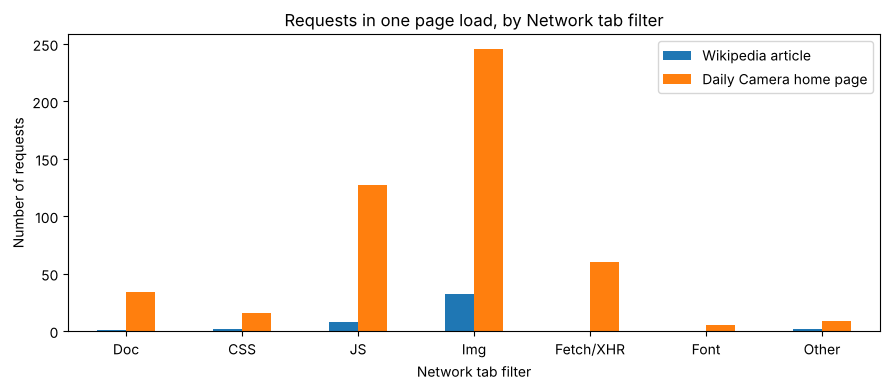

Wikipedia article          45
Daily Camera home page    497
dtype: int64
Wikipedia article         0.18
Daily Camera home page    0.26
dtype: float64


In [4]:
# Microsprint: put your counts in a dict of dicts, one per page: {"Wikipedia article": {"Doc": 1, "JS": 8, ...}, "<your site>": {...}}
# Make a DataFrame from it, and draw a bar chart (one group per filter) with a title and labeled axes
# Print each page's total number of requests, and the share of them that are JS
# The key's counts: one load of each page in headless Chromium on 2026-10-21, sorted into the Network tab's filters
counts = {
    "Wikipedia article": {"Doc": 1, "CSS": 2, "JS": 8, "Img": 32, "Fetch/XHR": 0, "Font": 0, "Other": 2},
    "Daily Camera home page": {"Doc": 34, "CSS": 16, "JS": 127, "Img": 246, "Fetch/XHR": 60, "Font": 5, "Other": 9},
}
by_type = pd.DataFrame(counts)

ax = by_type.plot.bar(figsize=(9, 4), rot=0)
ax.set_title("Requests in one page load, by Network tab filter")
ax.set_xlabel("Network tab filter")
ax.set_ylabel("Number of requests")
plt.tight_layout()
plt.show()

totals = by_type.sum()
print(totals)
print((by_type.loc["JS"] / totals).round(2))

<details>
<summary>💬 Discuss</summary>

- Your browser made dozens of requests for the article; `requests` made one. What does a scraper never see, and what does it spare the server?
- In week 3 we read the `server` and `via` headers to learn who refused us. What does Wikimedia's `x-cache` header let you say about who answered?
- A news home page can load hundreds of requests from dozens of hosts. Who learns that you visited it?

</details>

## Step 3 — Below HTTP: addresses, and one connection narrated (7 minutes)

HTTP rides on TCP/IP: every machine has an IP address, and a request travels as packets between two of them. [`socket`](https://docs.python.org/3/library/socket.html) asks your operating system for your machine's name and local address; a service like [ipify](https://www.ipify.org/) reports the public address servers see. Mask its last two numbers before you print it, as the chapter does, because notebooks end up on screens and in repositories.

Then let `curl` narrate one request. A line that starts with `!` runs in your terminal, and [`lines = !command`](https://ipython.readthedocs.io/en/stable/interactive/python-ipython-diff.html#shell-assignment) keeps its output as a list. `curl -v` narrates on its error stream, so add `2>&1` to keep it, and print only the lines for the connection (`* Connected`), the TLS handshake's result (`* SSL connection`), the request (`>`), and the response's status line (`< HTTP`). For more, see the chapter's *TCP/IP: The Transport Layer* and "Packets".

If there's time, the optional cell after it pings Wikipedia: four small packets out, four replies back. Campus Wi-Fi may drop them.

In [5]:
# Import socket. Print your hostname, and the address socket.gethostbyname() gives for it
# Get your public IP from https://api.ipify.org?format=json, and print it with its last two numbers replaced by xxx
# Run lines = !curl -v -I -A "<your User-Agent>" https://en.wikipedia.org/wiki/Web_scraping 2>&1 and print the lines
#   that start with "* Connected", "* SSL connection", ">", or "< HTTP"
import socket

hostname = socket.gethostname()
print(f"Hostname: {hostname}")
print(f"Local IP: {socket.gethostbyname(hostname)}")

public_ip = requests.get("https://api.ipify.org?format=json", headers=HEADERS, timeout=10).json()["ip"]
print("Public IP:", ".".join(public_ip.split(".")[:2] + ["xxx", "xxx"]))

lines = !curl -v -I -A "WebDataScience/1.0 (your-email@colorado.edu)" https://en.wikipedia.org/wiki/Web_scraping 2>&1
for line in lines:
    if line.startswith(("* Connected", "* SSL connection", ">", "< HTTP")):
        print(line)

Hostname: vm
Local IP: 127.0.0.1


Public IP: 160.79.xxx.xxx


* Connected to 127.0.0.1 (127.0.0.1) port 35529
> CONNECT en.wikipedia.org:443 HTTP/1.1
> Host: en.wikipedia.org:443
> User-Agent: WebDataScience/1.0 (your-email@colorado.edu)
> Proxy-Connection: Keep-Alive
> 
< HTTP/1.1 200 Connection Established
* SSL connection using TLSv1.3 / TLS_AES_128_GCM_SHA256 / X25519 / id-ecPublicKey
> HEAD /wiki/Web_scraping HTTP/2
> Host: en.wikipedia.org
> User-Agent: WebDataScience/1.0 (your-email@colorado.edu)
> Accept: */*
> 


In [ ]:
# Optional: ping Wikipedia four times (-n on Windows, -c on macOS and Linux)
import platform

if platform.system() == "Windows":
    !ping -n 4 en.wikipedia.org
else:
    !ping -c 4 en.wikipedia.org

<details>
<summary>💬 Discuss</summary>

- `socket.gethostbyname()` may give you 127.0.0.1, which means "this machine". Why is the public address the one a server's logs record?
- curl reports the connection done before it sends a byte of HTTP. Which layer did that work, and why doesn't curl show its three packets?
- Week 1 asked us to treat `requests` as a well-made black box. Which parts of what curl narrated does `requests` do for you without a word?

</details>

## Step 4 — DNS: from a name to an address (8 minutes)

Before any of that, the name had to become an address. [`dns.resolver.resolve()`](https://dnspython.readthedocs.io/en/stable/resolver-functions.html) asks a DNS server for a name's **A** records, its IPv4 addresses. The answer holds more than the address: `canonical_name` is the name the record belongs to, when the name you asked for is an alias, and `rrset.ttl` is how many seconds resolvers may cache the answer. `socket.gethostbyname()`, the lookup `requests` relies on, should agree. If `dns.resolver` raises `NoNameservers ... answered REFUSED`, see the chapter's *Common Issues to Debug*. For more, see the chapter's *DNS: The Address Book*.

In [6]:
# Import dns.resolver. Resolve en.wikipedia.org's A record, and print each address in the answer
# Print the answer's canonical_name and rrset.ttl, and what socket.gethostbyname("en.wikipedia.org") says
# Keep the first address, as a string, in WIKI_IP
import dns.resolver

answers = dns.resolver.resolve("en.wikipedia.org", "A")
for answer in answers:
    print(f"IP address: {answer}")
print(f"Canonical name: {answers.canonical_name}")
print(f"TTL: {answers.rrset.ttl} seconds")
print(f"socket says: {socket.gethostbyname('en.wikipedia.org')}")
WIKI_IP = str(answers[0])

IP address: 208.80.154.224
Canonical name: dyna.wikimedia.org.
TTL: 180 seconds
socket says: 208.80.154.224


### ⏱ Microsprint (5 minutes, alone or in pairs)

**Do:** find where that address is. Write the chapter's `geolocate_ip()`, from its traceroute section, which asks [ip-api](https://ip-api.com/docs/api:json) about an address, and look up `WIKI_IP`. Then print Step 1's `Server` header: Wikimedia names its servers after their data centers, and `eqiad` is Ashburn, Virginia; `codfw` is Carrollton, Texas.
**Share:** your address, the city ip-api gives it, and the data center in your `Server` header.

In [7]:
# Microsprint: define geolocate_ip(ip), as the chapter does, but with HEADERS: request http://ip-api.com/json/{ip} and return the JSON
# Look up WIKI_IP and print its city, regionName, and isp. Then print response.headers["Server"] from Step 1
# (ip-api allows 45 requests a minute from one address, and this room shares one)
def geolocate_ip(ip):
    """Look up the geographic location of an IP address."""
    response = requests.get(f"http://ip-api.com/json/{ip}", headers=HEADERS, timeout=10)
    return response.json()

location = geolocate_ip(WIKI_IP)
print(WIKI_IP, "|", location["city"], location["regionName"], "|", location["isp"])
print(response.headers["Server"])

208.80.154.224 | San Francisco California | Wikimedia Foundation Inc.
mw-web.eqiad.main-855b9df8d-fzg98


<details>
<summary>💬 Discuss</summary>

- In the key, ip-api put Wikipedia's address in San Francisco, where the Wikimedia Foundation has its office, while the `Server` header named a data center in Virginia or Texas. What does an IP geolocation service look up, and which answer do you believe?
- Did everyone in the room get the same address? Why might someone on a phone hotspot get a different one?
- Resolvers may keep this answer for `ttl` seconds. If Wikipedia moved its servers tomorrow, how long could some of us still be sent to the old address?

</details>

## Step 5 — Status codes, and a function that reads them (10 minutes)

HTTP is the layer you talk to. A response's [status code](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Status) is the server's verdict: 200 OK; 301 or 302, moved (the `Location` header says where); 403, refused; 404, not found; 429, slow down; 500, the server's own failure. Write the chapter's `diagnose_request(url, headers=None)`, which prints the status, `Content-Type`, `Server`, size, and, if `requests` followed a redirect, where from (`response.history`). Try it on the article, on a page that doesn't exist, and on the article again without `HEADERS`, to check the chapter's claim that Wikipedia answers an unnamed client with a 403. Then read the 403's body. For more, see the chapter's "Diagnosing HTTP Errors".

In [8]:
# Define diagnose_request(url, headers=None), as the chapter does: request url (timeout=10) and print the URL, status,
#   Content-Type, Server, size in bytes, and, if response.history isn't empty, the URL it was redirected from; return the response.
#   Catch requests.exceptions.ConnectionError and Timeout, and print which happened
# Run it with HEADERS on PAGE and on .../wiki/Nonexistent_Page_12345; then on PAGE with no headers, and print that body's first 120 characters
def diagnose_request(url, headers=None):
    """Print diagnostic information about an HTTP request."""
    try:
        response = requests.get(url, headers=headers, timeout=10)
        print(f"URL: {url}")
        print(f"Status: {response.status_code}")
        print(f"Content-Type: {response.headers.get('Content-Type', 'not specified')}")
        print(f"Server: {response.headers.get('Server', 'not specified')}")
        print(f"Response size: {len(response.content):,} bytes")
        if response.history:
            print(f"Redirected from: {response.history[0].url}")
        return response
    except requests.exceptions.ConnectionError:
        print(f"Connection failed: {url}")
    except requests.exceptions.Timeout:
        print(f"Request timed out: {url}")

diagnose_request(PAGE, headers=HEADERS)
print()
diagnose_request("https://en.wikipedia.org/wiki/Nonexistent_Page_12345", headers=HEADERS)
print()
anonymous = diagnose_request(PAGE)
print(anonymous.text[:120])

URL: https://en.wikipedia.org/wiki/University_of_Colorado_Boulder
Status: 200
Content-Type: text/html; charset=UTF-8
Server: mw-web.codfw.main-c9fb77d8f-6khgv
Response size: 768,029 bytes



URL: https://en.wikipedia.org/wiki/Nonexistent_Page_12345
Status: 404
Content-Type: text/html; charset=UTF-8
Server: mw-web.eqiad.main-855b9df8d-859p7
Response size: 50,827 bytes



URL: https://en.wikipedia.org/wiki/University_of_Colorado_Boulder
Status: 403
Content-Type: text/plain
Server: HAProxy
Response size: 126 bytes
Please set a user-agent and respect our robot policy https://w.wiki/4wJS. See also https://phabricator.wikimedia.org/T40


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** follow redirects by hand. Request `https://en.wikipedia.org/` and `https://en.wikipedia.org/wiki/CU_Boulder` with [`allow_redirects=False`](https://requests.readthedocs.io/en/latest/user/quickstart/#redirection-and-history), and print each one's status code and `Location` header. Then request `CU_Boulder` normally, and print its `response.history` and the title in its `#firstHeading`.
**Share:** the two status codes, and the page each address ended up on.

In [9]:
# Microsprint: request each of the two URLs with HEADERS and allow_redirects=False; print the URL, status code, and Location header
# Then request the CU_Boulder URL normally: print response.url, response.history, and the text of its #firstHeading
for url in ["https://en.wikipedia.org/", "https://en.wikipedia.org/wiki/CU_Boulder"]:
    hop = requests.get(url, headers=HEADERS, timeout=10, allow_redirects=False)
    print(url, hop.status_code, hop.headers.get("Location"))

alias = requests.get("https://en.wikipedia.org/wiki/CU_Boulder", headers=HEADERS, timeout=10)
print(alias.url, alias.history)
print(BeautifulSoup(alias.text, "lxml").select_one("#firstHeading").text)

https://en.wikipedia.org/ 301 https://en.wikipedia.org/wiki/Main_Page


https://en.wikipedia.org/wiki/CU_Boulder 200 None


https://en.wikipedia.org/wiki/CU_Boulder []
University of Colorado Boulder


<details>
<summary>💬 Discuss</summary>

- The 403 came with a `Server` header and a body. In week 3 we read both before blaming a platform for a refusal. Who refused us here, and how do you know?
- `CU_Boulder` answered 200 but showed another article's title. What would a check of the status code alone have missed?
- A 404 page is still a page, with a size and a Content-Type. Why did week 2's `responsible_get()` call `raise_for_status()` instead of checking whether text came back?

</details>

## Step 6 — Ask the pageviews API, politely (7 minutes)

Now an API. The [Wikimedia pageviews API](https://doc.wikimedia.org/generated-data-platform/aqs/analytics-api/reference/page-views.html) puts every parameter in the URL's path: project, access, agent, article, granularity, start, and end. Without a User-Agent that names you, it answers 403. When many clients share one address, as this room does, it may answer 429, with a [`Retry-After`](https://developer.mozilla.org/en-US/docs/Web/HTTP/Reference/Headers/Retry-After) header saying how many seconds to wait. The chapter's `get_with_backoff()` waits that long, or 1, 2, then 4 seconds if the header is missing, and tries again; give its request a timeout too. Use January 2026, the chapter's window, so your numbers match the key's. For more, see the chapter's "Making API Requests with Custom Headers".

In [10]:
# Import time. Define get_with_backoff(url, headers=None, max_retries=3), as the chapter does (add timeout=30): on a 429,
#   sleep for Retry-After seconds if it's a number, otherwise 2 ** attempt, and try again; return the last response
# Build api_url: per-article pageviews for ARTICLE on en.wikipedia, all-access, all-agents, daily, 20260101 to 20260131
# Request it with no headers and print the status. Then get_with_backoff() it with HEADERS, print the status, raise_for_status(), keep .json() as data
import time

def get_with_backoff(url, headers=None, max_retries=3):
    """Retry a request with exponential backoff on 429 errors."""
    for attempt in range(max_retries):
        response = requests.get(url, headers=headers, timeout=30)
        if response.status_code == 429:
            retry_after = response.headers.get("Retry-After")
            if retry_after and retry_after.isdigit():
                wait_time = int(retry_after)  # the server told us how long to wait
            else:
                wait_time = 2 ** attempt  # 1s, 2s, 4s
            print(f"Rate limited. Waiting {wait_time}s before retry...")
            time.sleep(wait_time)
        else:
            return response
    return response  # Return the last response even if still 429

api_url = (
    "https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article"
    f"/en.wikipedia/all-access/all-agents/{ARTICLE}/daily/20260101/20260131"
)
print(requests.get(api_url, timeout=30).status_code)

response = get_with_backoff(api_url, headers=HEADERS)
print(response.status_code)
response.raise_for_status()
data = response.json()
print(len(data["items"]), "days; the first:", data["items"][0])

403


200
31 days; the first: {'project': 'en.wikipedia', 'article': 'University_of_Colorado_Boulder', 'granularity': 'daily', 'timestamp': '2026010100', 'access': 'all-access', 'agent': 'all-agents', 'views': 657}


<details>
<summary>💬 Discuss</summary>

- In week 1 we called this same API and got data back the first time. What did that request already carry that today's first one lacked?
- A 429 here counts everyone on your network, not only you. Why is waiting for `Retry-After` better than week 2's fixed `time.sleep(1)`?
- Why put a fixed date range in the URL rather than asking for "the last 30 days"?

</details>

## Step 7 — From JSON to a time series (9 minutes)

The views sit under `data["items"]`, one dictionary per day: week 4's list-of-dictionaries pattern, which `pd.DataFrame()` turns into a table in one call. Turn `timestamp`, written year, month, day, and hour (`2026010100`), into dates with [`pd.to_datetime()`](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html) and `format="%Y%m%d00"`. Plot views by date with a title and labeled axes, and find the biggest day with `idxmax()`. For more, see the end of the chapter's "Making API Requests with Custom Headers".

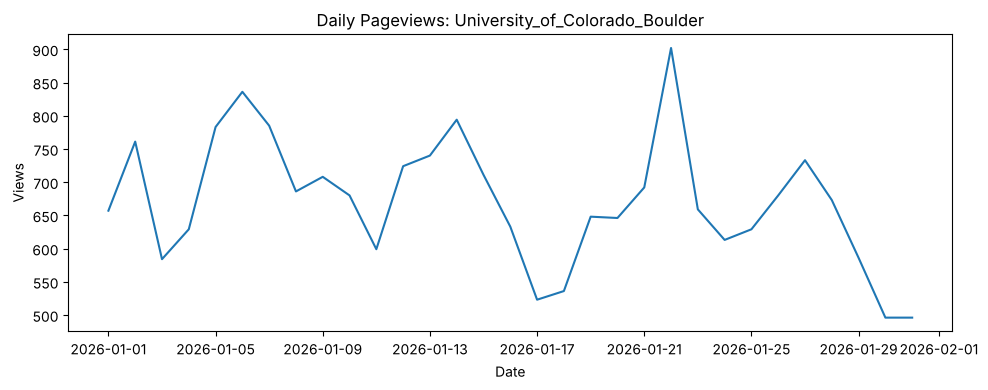

2026-01-22 902 views


In [11]:
# Make a DataFrame from data["items"], and turn its timestamp into dates (format="%Y%m%d00")
# Plot views by date, with a title and labeled axes
# Print the day with the most views, and how many
df = pd.DataFrame(data["items"])
df["timestamp"] = pd.to_datetime(df["timestamp"], format="%Y%m%d00")

plt.figure(figsize=(10, 4))
plt.plot(df["timestamp"], df["views"])
plt.title(f"Daily Pageviews: {ARTICLE}")
plt.xlabel("Date")
plt.ylabel("Views")
plt.tight_layout()
plt.show()

peak = df.loc[df["views"].idxmax()]
print(peak["timestamp"].date(), f"{peak['views']:,} views")

### ⏱ Microsprint (6 minutes, alone or in pairs)

**Do:** a short version of Additional Exercise 3. Get the same month's daily views for two articles related to ours (another university, the city, a team), and plot all three on one set of axes.
**Share:** your two articles, which of the three had the biggest spike, on what day, and a guess at why.

Rate limited. Waiting 1s before retry...


Rate limited. Waiting 1s before retry...


Rate limited. Waiting 1s before retry...


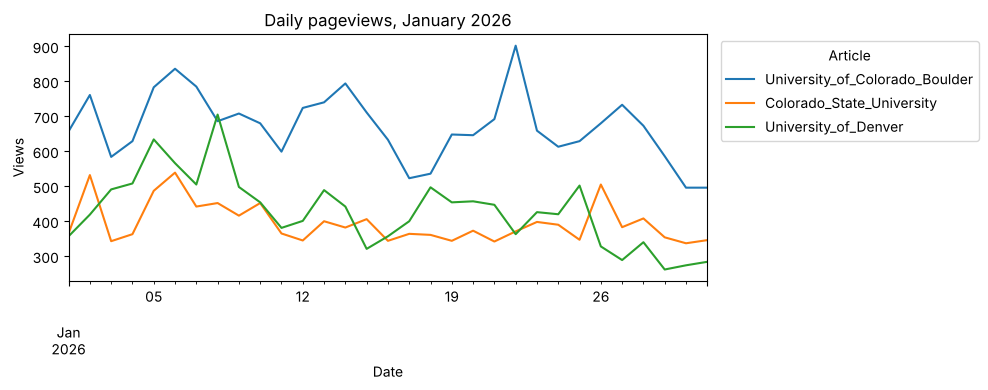

University_of_Colorado_Boulder 2026-01-22 902 views
Colorado_State_University 2026-01-06 539 views
University_of_Denver 2026-01-08 705 views


In [12]:
# Microsprint: for two related articles, build the same URL, get_with_backoff() it with HEADERS, raise_for_status(), and time.sleep(1) between
# Put all three articles' daily views in one DataFrame (one column each), and plot it with a title, labeled axes, and a legend
# Print each article's biggest day and its views
related = ["Colorado_State_University", "University_of_Denver"]
series = {ARTICLE: df.set_index("timestamp")["views"]}
for title in related:
    url = (
        "https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article"
        f"/en.wikipedia/all-access/all-agents/{title}/daily/20260101/20260131"
    )
    reply = get_with_backoff(url, headers=HEADERS)
    reply.raise_for_status()
    views = pd.DataFrame(reply.json()["items"])
    views["timestamp"] = pd.to_datetime(views["timestamp"], format="%Y%m%d00")
    series[title] = views.set_index("timestamp")["views"]
    time.sleep(1)

compare = pd.DataFrame(series)
ax = compare.plot(figsize=(10, 4))
ax.set_title("Daily pageviews, January 2026")
ax.set_xlabel("Date")
ax.set_ylabel("Views")
ax.legend(title="Article", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

for title in compare.columns:
    print(title, compare[title].idxmax().date(), f"{compare[title].max():,} views")

<details>
<summary>💬 Discuss</summary>

- What happened on the biggest day? How would you check it, rather than guess?
- These are `all-agents` counts, crawlers included. Which claims about attention can this plot support, and which can't it?
- Week 1 plotted this article's same January. Should your numbers match the ones you got then, and why?

</details>

## Step 8 — What a server sees: honest and spoofed User-Agents (4 minutes)

A `User-Agent` is whatever the client says it is. [httpbin.org](https://httpbin.org/)'s `/user-agent` endpoint echoes back the header it received, so you can see exactly what a server gets: `requests`' default, your honest identification, and a **spoofed** one that claims to be desktop Chrome. Spoofing is the same dictionary with a false value. The chapter's callout explains why this course doesn't use it to get past a block. For more, see the chapter's "User-Agent Spoofing".

In [13]:
# Define spoofed_headers, whose User-Agent claims to be Chrome on Windows (copy the chapter's string)
# Ask https://httpbin.org/user-agent three times and print the JSON: with no headers, with HEADERS, and with spoofed_headers
spoofed_headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
        "(KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36"
    )
}
for headers in [None, HEADERS, spoofed_headers]:
    print(requests.get("https://httpbin.org/user-agent", headers=headers, timeout=10).json())

{'user-agent': 'python-requests/2.34.2'}


{'user-agent': 'WebDataScience/1.0 (your-email@colorado.edu)'}


{'user-agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36'}


<details>
<summary>💬 Discuss</summary>

- By this header alone, the server can't tell the spoofed request from Chrome. What else could it check? Step 2's comparison of request headers is a hint.
- Week 2 asked whether a collection is consistent with a site's terms. When is changing your User-Agent unremarkable, and when does it become getting around a block?

</details>

## Step 9 — A Session that reuses its connection and retries (8 minutes)

Each bare `requests.get()` opens a connection, does the TLS handshake Step 3 narrated, and closes it. A [`requests.Session`](https://requests.readthedocs.io/en/latest/user/advanced/#session-objects) keeps the connection open for the next request to the same host, and remembers your headers. Mount an `HTTPAdapter` with a [`Retry`](https://urllib3.readthedocs.io/en/stable/reference/urllib3.util.html#urllib3.util.Retry) rule, and it retries 429s and server errors for you, honoring `Retry-After`, as `get_with_backoff()` did by hand. For more, see the chapter's "Connections, Sessions, and Retries".

In [14]:
# Make a Session, put HEADERS in session.headers, and mount HTTPAdapter(max_retries=Retry(total=3, backoff_factor=1,
#   status_forcelist=[429, 500, 502, 503, 504])) on it for "https://"
# Loop over the chapter's three articles: get each with the session (timeout=30), and print its title, status, and length
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

session = requests.Session()
session.headers.update(HEADERS)
retries = Retry(total=3, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504])
session.mount("https://", HTTPAdapter(max_retries=retries))

articles = ["Python_(programming_language)", "Web_scraping", "Data_science"]
for article in articles:
    url = f"https://en.wikipedia.org/wiki/{article}"
    response = session.get(url, timeout=30)
    print(article, response.status_code, len(response.text))

Python_(programming_language) 200 1012849
Web_scraping 200 235982
Data_science 200 283350


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** check the chapter's claim that a Session saves work. Time three bare `requests.get()` calls for the same three articles with [`time.perf_counter()`](https://docs.python.org/3/library/time.html#time.perf_counter), then three `session.get()` calls.
**Share:** the two times, and how much the Session saved.

In [15]:
# Microsprint: time three bare requests.get() calls (with HEADERS, timeout=30) for the same three articles, using time.perf_counter()
# Then time three session.get() calls for them, and print both times in seconds
start = time.perf_counter()
for article in articles:
    requests.get(f"https://en.wikipedia.org/wiki/{article}", headers=HEADERS, timeout=30)
bare = time.perf_counter() - start

start = time.perf_counter()
for article in articles:
    session.get(f"https://en.wikipedia.org/wiki/{article}", timeout=30)
reused = time.perf_counter() - start

print(f"bare requests.get(): {bare:.2f} s; session.get(): {reused:.2f} s")

bare requests.get(): 1.18 s; session.get(): 0.19 s


<details>
<summary>💬 Discuss</summary>

- Is this a fair race? The session's connection was already open from the step above. What would make the comparison fairer?
- Week 2 asked for a pause between requests. Does a Session make a loop polite on its own?
- Which costs does reusing a connection save the server, not just you?

</details>

## Step 10 — Take a URL apart, and build one safely (8 minutes)

Don't parse URLs with regular expressions: [`urllib.parse`](https://docs.python.org/3/library/urllib.parse.html) knows their grammar, `scheme://host:port/path?query#fragment`. `urlparse()` splits a URL into its parts, and `parse_qs()` turns its query into a dictionary. Building goes the other way, in two patterns. A **path-segment** API, like pageviews, needs each value made safe for its slot with `quote(value, safe="")`. A **query-parameter** API, like the MediaWiki Action API, takes a dictionary, which `urlencode()` escapes, or which `requests` escapes for you when you pass it as `params=`. For more, see the chapter's *URLs: Anatomy and Parsing*.

In [16]:
# From urllib.parse import urlparse, parse_qs, quote, and urlencode. urlparse() the chapter's Census URL: print its scheme, host, path, and parse_qs(query)
# quote() "University of Colorado Boulder" for a path segment: spaces to underscores first, and safe=""
# urlencode() the chapter's Action API params (action=query, format=json, titles, prop=info); then session.get() them with params= and print response.url and the status
from urllib.parse import urlparse, parse_qs, quote, urlencode

census_url = "https://api.census.gov/data/2022/acs/acs5?get=NAME,B01001_001E&for=place:07850&in=state:08"
parsed = urlparse(census_url)
print(f"Scheme: {parsed.scheme}")
print(f"Host: {parsed.netloc}")
print(f"Path: {parsed.path}")
print(parse_qs(parsed.query))

print(quote("University of Colorado Boulder".replace(" ", "_"), safe=""))

base_url = "https://en.wikipedia.org/w/api.php"
params = {"action": "query", "format": "json", "titles": "University of Colorado Boulder", "prop": "info"}
print(urlencode(params))
response = session.get(base_url, params=params, timeout=30)
print(response.url)
print(response.status_code)

Scheme: https
Host: api.census.gov
Path: /data/2022/acs/acs5
{'get': ['NAME,B01001_001E'], 'for': ['place:07850'], 'in': ['state:08']}
University_of_Colorado_Boulder
action=query&format=json&titles=University+of+Colorado+Boulder&prop=info
https://en.wikipedia.org/w/api.php?action=query&format=json&titles=University+of+Colorado+Boulder&prop=info
200


### ⏱ Microsprint (4 minutes, alone or in pairs)

**Do:** check the chapter's warning about slashes. Build January 2026's pageviews URL for the article `AC/DC` twice: once with the raw title in the f-string, once with `quote(title, safe="")`. Request both with your session.
**Share:** the two status codes, and what the server took the raw slash to mean.

In [17]:
# Microsprint: for the title "AC/DC", build January 2026's daily pageviews URL twice: with the raw title, and with quote(title, safe="")
# Request both with session.get(), and print the part of each URL's path after "all-agents/", and the status code
title = "AC/DC"
for segment in [title, quote(title, safe="")]:
    url = (
        "https://wikimedia.org/api/rest_v1/metrics/pageviews/per-article"
        f"/en.wikipedia/all-access/all-agents/{segment}/daily/20260101/20260131"
    )
    reply = session.get(url, timeout=30)
    print(urlparse(url).path.split("all-agents/")[1], reply.status_code)

AC/DC/daily/20260101/20260131 404


AC%2FDC/daily/20260101/20260131 200


<details>
<summary>💬 Discuss</summary>

- `quote("AC/DC")` without `safe=""` leaves the slash alone. Why is that the default, and why is it wrong for a path segment?
- Look at the Action API's `response.url`. Which characters did `requests` escape, and how?
- Week 3's access matrix probed APIs of both kinds. How can you tell from a URL alone which kind you have? Name one of each from that list.

</details>

## Step 11 — What did we learn? (5 minutes)

In a few sentences, as comments or in a Markdown cell:

- In Step 2 and its microsprint, how many requests did your browser make for the article, and for the news site? What does a scraper that sends one request never see?
- Which of today's outputs (Steps 3 and 4 above all) describe your own network or machine rather than Wikipedia?
- Which status codes did we meet in Steps 5 and 6, and which response would a check of the status code alone have read wrongly?
- Why did the raw `AC/DC` URL in Step 10's microsprint fail, and what told you?

**Recommended Exercises ahead** (in the chapter's companion notebook, due Sunday):

- Step 1, take a URL apart: Step 10's `urlparse()` of the Census URL.
- Step 2, resolve a name: Step 4's `dns.resolver.resolve()`.
- Step 3, request with named headers: Step 0's `HEADERS`, and Step 2's reading of response headers (and why `Content-Length` and `len(response.content)` differ).
- Step 4, write `diagnose_url()`: Step 5's `diagnose_request()`, and its microsprint's redirects (`Location`, `response.history`).
- Step 5, profile five URLs: Steps 5 and 6 (a page, a 404, a refusal, an API), and week 3's habit of reading a refusal's `Server` header and body.
- Step 6, interpret: Step 2's compressed and decompressed sizes, Step 5's `Content-Type` and `Server` headers, and week 3's question of who answered.

In [18]:
# Your answers here, as comments
# Step 2: the key's page loads made 45 requests for the article and 497 for the Daily Camera's home page
#   (26% of them scripts); requests made 1, and got 768,062 bytes of HTML, sent as 121,506 gzipped bytes.
#   A scraper never sees the scripts, images, and Fetch/XHR data the browser loads after the HTML.
# Our network, not Wikipedia: the local IP 127.0.0.1, the public IP (the proxy's, in the key), curl's
#   CONNECT to the proxy, and the DNS answer (208.80.154.224, cacheable for 180 s), which depends on where you
#   ask from. ip-api's "San Francisco" describes who registered the address, not where the server is.
# We met 200, 301 (en.wikipedia.org/ to Main_Page), 403 (HAProxy, text/plain, 126 bytes, about our missing
#   User-Agent), 404 (a 50,827-byte page), and 429s that get_with_backoff() waited out. CU_Boulder answered
#   200 with another article's title: a status-only check would read it as the page we asked for.
# The raw "AC/DC" put a slash in the path, so the API read two segments and answered 404;
#   quote(title, safe="") sent AC%2FDC and got 200. The status code told us; nothing else warned us.

## Friday: from the lab to the textbook (15 minutes)

Did anything in this lab disagree with chapter 5? Places to look:

- **Step 4's microsprint.** The chapter maps traceroute hops with `geolocate_ip()`, but ip-api placed Wikipedia's address in San Francisco, at the Foundation's office, while the `Server` header named a data center in Virginia or Texas. Should the chapter say what an IP geolocation service looks up?
- **The helpers.** The chapter's `geolocate_ip()` sends no User-Agent, and `get_with_backoff()` sets no timeout, though chapter 2 asks for both. We added them here.
- **Outputs that have moved.** The chapter's Network tab figure counts 37 requests for the article, and its `Session` example prints page lengths from when it was written. What did you get?
- **A cell that broke for you,** such as `ping` on campus Wi-Fi, or `dns.resolver` off campus. Is the chapter's *Common Issues to Debug* enough?
- **A microsprint that would make a good exercise,** such as Step 10's `AC/DC` check.

[`handouts/common/revision-framework.md`](../../handouts/common/revision-framework.md) says how to propose a revision.